# B-cell receptors in tissue: class switching, somatic mutation and lineages

When receptor positions pass the trust tests (`02_is_my_data_spatial`), the BCR itself carries biology that single-cell
data cannot place: which isotypes a clone has switched to, how mutated its members are, and where the branches of its
lineage tree sit in the tissue. This notebook works through that on one AIR-SPACE lymph node, day 21 after vaccinia
infection (Jiang et al., *PNAS* 2026; GEO GSE286452), a time with mature germinal centres (GCs).

Each AIR-SPACE molecule is one nanopore consensus read through V(D)J and the constant region, so every heavy-chain
molecule has its own isotype, and MiXCR's alignment records its V-gene substitutions.

The steps: regions from the transcriptome → isotypes and inferred cells (loci) → switched-share map with family-wise
hotspots → isotype transitions within clones → somatic hypermutation → lineage trees with tissue positions.

In [1]:
import re
import time

t_start = time.time()

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import spaclone
from spaclone import bcr, gex, io, pl, pp, tl

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 100
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # one-line warnings
print("spaclone", spaclone.__version__)

spaclone 1.0.0


## The data

The D21 node is built into `spaclone.datasets`: `spaclone.datasets.airspace("D21")` downloads the bead counts and the
clone table from GEO once (about 78 MB; needs `pip install "spaclone[datasets]"`) into the user cache (or the folder
in the environment variable `SPACLONE_DATA_DIR`), checks their sha256 and returns the two paths; later calls only
verify the files.

In [2]:
h5ad, clone_table = spaclone.datasets.airspace("D21")
sa = io.read_airspace(h5ad, clone_table)
G = sa.gex
print(h5ad.name, "|", clone_table.name)
print({k: sa.meta[k] for k in ("n_beads", "n_tissue_beads", "n_records", "records_by_locus")})

GSM8727834_adata_D21_with_image_raw_counts.h5ad | GSM8727840_D21_ovp_clone_table.txt.gz
{'n_beads': 79423, 'n_tissue_beads': 23040, 'n_records': 17173, 'records_by_locus': {'IGH': 3185, 'IGK': 11263, 'IGL': 1584, 'TRA': 273, 'TRB': 868}}


## 1. Regions from the transcriptome

Germinal centres are called from the GEX alone, so that they are independent of the receptor data tested in them
(`gex.call_regions`, kind `"germinal_centre"`: beads whose share of GC B-cell marker counts within 30 µm (Aicda,
S1pr2, Gcsam, Rgs13, Mef2b) is in the top 8% of tissue beads, clustered with DBSCAN (25 µm, 8 beads), clusters of
≥ 30 beads kept and widened by 25 µm). The plasma-cell area (`"plasma_cell"`) uses Jchain, Xbp1, Prdm1 and Sdc1 the
same way, without instances.

In [3]:
gcs = gex.call_regions(G, kind="germinal_centre")
gex.call_regions(G, kind="plasma_cell")
print(G.obs["region"].value_counts().to_dict())
gcs[["region_id", "n_core", "n_units", "x_um", "y_um"]]

{'other': 19240, 'GC': 1987, 'ASC': 1813}


,region_id,n_core,n_units,x_um,y_um
0,GC_0,440,662,1693.077485,2628.979199
1,GC_1,150,265,1085.174264,1789.733547
2,GC_2,189,293,2007.494386,1278.325939
3,GC_3,79,144,1842.211042,804.508160
4,GC_4,81,129,1413.606395,1034.003372
5,GC_5,81,125,1338.871560,1199.862560
6,GC_6,52,102,2158.696520,1182.831765
7,GC_7,95,160,2026.833656,1092.802750
8,GC_8,56,107,1867.045421,1090.542664


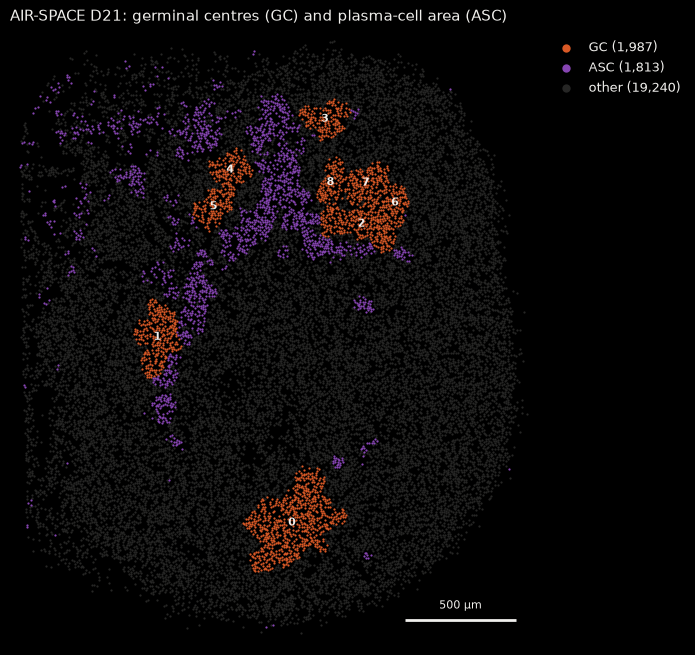

In [4]:
in_tissue = G.obs["in_tissue"].to_numpy()
ax = pl.gex_regions(G[in_tissue], title="AIR-SPACE D21: germinal centres (GC) and plasma-cell area (ASC)")
plt.show()

## 2. Isotypes and inferred cells

We keep IGH molecules on tissue with a valid junction, and `bcr.isotype` turns each constant-gene call into a class
(IgM, IgD, IgG, IgA, IgE), a subclass and a switched flag (IgG, IgA and IgE are switched).

In [5]:
igh = pp.filter_records(sa.air, on_tissue=True, loci="IGH").air.reset_index(drop=True)
igh = bcr.isotype(igh, species="mouse")
igh["region"] = igh["spot_id"].map(G.obs["region"].astype(str)).to_numpy()
pd.crosstab(igh["region"], igh["isotype_subclass"].astype("string").fillna("unknown"), margins=True)

isotype_subclass,IgD,IgE,IgG1,IgG2b,IgG2c,IgG3,IgM,unknown,All
region,,,,,,,,,
ASC,5,1,130,350,467,3,31,12,999
GC,3,0,28,76,66,1,13,4,191
other,70,3,151,432,515,8,132,41,1352
All,78,4,309,858,1048,12,176,57,2542


Day 21 is dominated by IgG2c and IgG2b, the Th1-type response to a virus; IgM and IgD (unswitched) are 10% of the
heavy-chain molecules.

A plasma cell can put dozens of molecules of its clone on neighbouring beads. To count cells rather than molecules,
`pp.merge_loci` merges same-clone molecules within 15 µm into a *locus* (one inferred cell), and `bcr.call_isotype`
calls each locus switched when at least half of its isotyped molecules are switched.

In [6]:
loci, membership = pp.merge_loci(igh, radius_um=15)
igh["locus_id"] = membership.to_numpy()
units = loci.join(bcr.call_isotype(igh, by="locus").drop(columns="n_records"), on="locus_id")
units["region"] = units["spot_id"].map(G.obs["region"].astype(str)).to_numpy()
gc_id = units["spot_id"].map(G.obs["region_id"]).astype("string")
units["gc_number"] = gc_id.str.removeprefix("GC_").astype("float").add(1).fillna(0).astype(int)  # GC_k -> k+1; 0 = no GC
print(f"{len(igh):,} IGH molecules -> {len(units):,} loci; per region:", units["region"].value_counts().to_dict())
units[["locus_id", "clone_id", "x_um", "y_um", "n_records", "isotype", "switched", "region", "gc_number"]].head()

2,542 IGH molecules -> 2,232 loci; per region: {'other': 1224, 'ASC': 845, 'GC': 163}


,locus_id,clone_id,x_um,y_um,n_records,isotype,switched,region,gc_number
0,0,1016,2342.21,729.495,1,IgM,False,other,0
1,1,1017,984.75,1238.250,1,unknown,<NA>,other,0
2,2,1017,1138.28,2124.070,1,IgM,False,ASC,0
3,3,1035,2462.20,1053.650,1,IgG,True,other,0
4,4,1035,551.59,2628.600,1,IgG,True,other,0


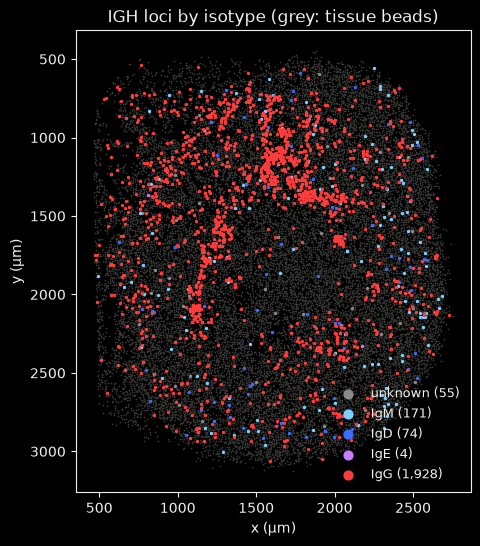

In [7]:
beads = pd.DataFrame({"x_um": G.obsm["spatial"][in_tissue, 0], "y_um": G.obsm["spatial"][in_tissue, 1],
                      "region": G.obs["region"].astype(str).to_numpy()[in_tissue]})
ax = pl.isotype_map(units, background=beads, s=6, title="IGH loci by isotype (grey: tissue beads)")
plt.show()

## 3. Where is the switched share high? A map with family-wise hotspots

`bcr.csr_hotspots` smooths the switched calls of the loci with a Gaussian kernel (σ = 50 µm) on a 10 µm grid of the
tissue, keeping pixels with at least 10 effective loci, and asks which pixels are higher than chance. A clone expands
after it switches, so its loci share their isotype; the null therefore relabels whole clones: clones with the same
number of isotyped loci trade their switched calls, 1,000 times, with every position fixed. Each pixel is standardised
by the mean and standard deviation of its shuffled values (the permutation-studentised z that the map shows), and a
hotspot is a connected set of pixels above the 95th percentile of the shuffled maps' *maximum*. So the chance of any
false hotspot anywhere on the map is 5%, however many pixels there are, and one expanded switched clone cannot make a
hotspot on its own.

In [8]:
grid = tl.Grid.from_points(beads["x_um"], beads["y_um"], pixel_um=10.0)
tissue = tl.tissue_mask(beads, grid=grid)
gc_mask = tl.tissue_mask(beads[beads["region"] == "GC"], grid=grid)
csr = bcr.csr_hotspots(units, tissue=tissue, grid=grid, n_perm=1000, rng=0)
print(csr)
csr.table[["hotspot", "area_um2", "units", "marked", "share", "expected", "p_value"]]

TestResult(hotspots: n_hotspots=2, n_coldspots=0, threshold_hot=2.594, max_z=2.99, min_z=-5.507, p0=0.8879; table 2×18)


,hotspot,area_um2,units,marked,share,expected,p_value
0,1,11800.0,48,48,1.0,42.620119,0.008991
1,2,3400.0,17,17,1.0,15.094626,0.014985


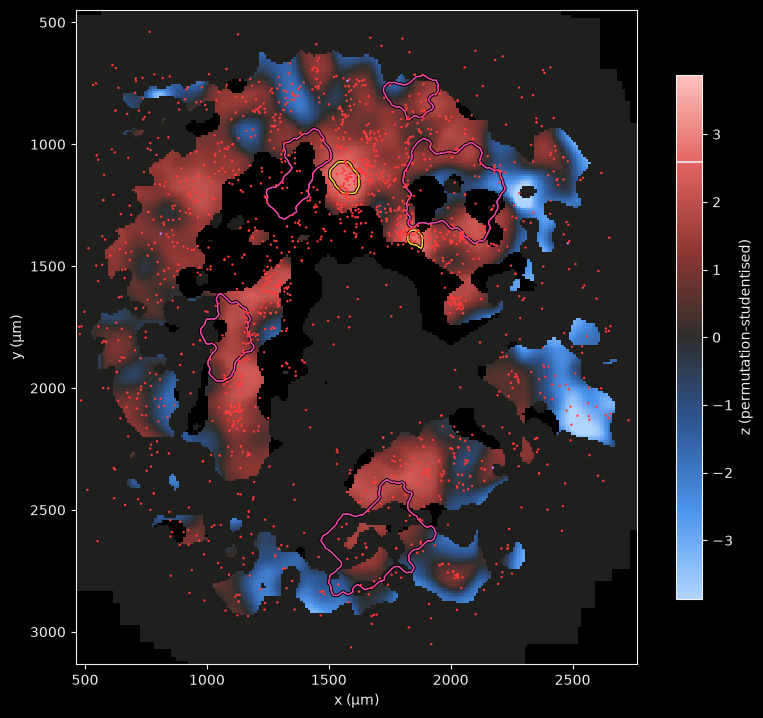

In [9]:
fig, ax = plt.subplots(figsize=(10, 8.5))
pl.csr_share_map(csr, units=units, outlines={"germinal centre": gc_mask}, ax=ax, s=3)
plt.show()

89% of isotyped loci are switched, so most of the node sits near or above its expectation (red), and the shuffles find
two small hotspots (yellow outlines; 48 and 17 loci, all switched). The blue parts, where unswitched loci gather, lie
in the follicles around the GCs (pink outlines).

Do germinal centres hold more switched loci than the rest of the node? `bcr.region_test` compares each GC's switched
loci with the count expected from the node-wide switched share, against 10,000 relabellings of whole clones:

In [10]:
rt_sw = bcr.region_test(units, regions=units["gc_number"].to_numpy(), mark="switched", match_by=None, rng=0)
rt_sw.table[["region", "units", "marked", "expected", "ratio", "p_value", "q_value"]]

,region,units,marked,expected,ratio,p_value,q_value
0,1,31,27,27.525494,0.980909,0.343866,0.728027
1,2,28,27,24.861736,1.086006,0.038596,0.347365
2,3,26,24,23.085898,1.039596,0.371763,0.728027
3,4,20,18,17.758383,1.013606,0.404460,0.728027
4,5,12,12,10.655030,1.126229,0.281172,0.728027
5,6,9,8,7.991272,1.001092,0.645135,0.829460
6,7,11,8,9.767111,0.819075,0.897110,0.897110
7,8,7,5,6.215434,0.804449,0.879312,0.897110
8,9,16,15,14.206706,1.055839,0.490351,0.735526
9,all,160,144,142.067065,1.013606,0.039196,NaN


Barely: the GCs hold 160 isotyped loci, 144 (90%) of them switched, against 142 expected from the node-wide share
(ratio 1.01). Relabelling whole clones gives a tight null, so this 1% excess reaches p = 0.04 pooled over the GCs, but
no single GC passes BH (smallest q = 0.35; regions are numbered GC_0 → 1, ..., GC_8 → 9). At day 21 switching has
happened everywhere, and the GCs differ little from the rest of the node in this respect.

## 4. Class switching within clones

Class switch recombination only moves 3' along the IgH locus (IgM → IgG3 → IgG1 → IgG2b → IgG2c → IgE → IgA in
mouse). A clone holding an upstream and a downstream isotype switched between them, or descends from a cell upstream
of both. `bcr.csr_transitions` counts, for every pair, the clones that hold both, and compares that with random
labelling of the loci (isotype labels shuffled among all loci; clone sizes and label counts fixed).

In [11]:
tr = bcr.csr_transitions(igh, species="mouse", level="subclass", unit_key="locus_id", n_perm=1000, rng=0)
tr.table.query("n_clones_both > 0")[["upstream", "downstream", "n_clones_both", "statistic", "null_mean", "ratio",
                                      "p_value"]]

,upstream,downstream,n_clones_both,statistic,null_mean,ratio,p_value
1,IgM,IgG3,1,1.0,3.949,0.253229,0.997003
2,IgM,IgG1,5,5.0,50.324,0.099356,1.000000
3,IgM,IgG2b,6,6.0,71.942,0.083401,1.000000
4,IgM,IgG2c,6,6.0,75.289,0.079693,1.000000
8,IgD,IgG2b,2,2.0,39.201,0.051019,1.000000
9,IgD,IgG2c,1,1.0,40.622,0.024617,1.000000
11,IgG3,IgG1,1,1.0,4.890,0.204499,1.000000
12,IgG3,IgG2b,2,2.0,6.411,0.311964,1.000000
13,IgG3,IgG2c,2,2.0,6.640,0.301205,1.000000
15,IgG1,IgG2b,12,12.0,98.853,0.121392,1.000000


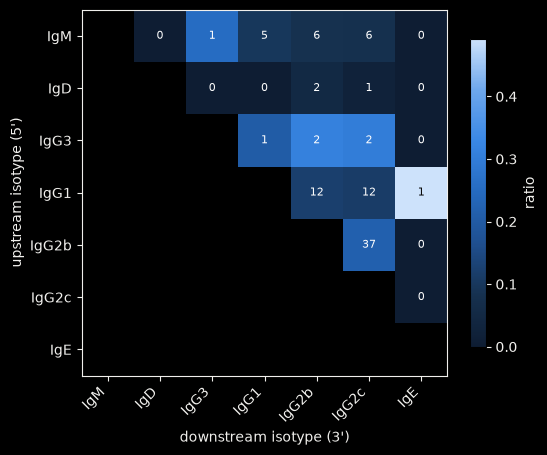

In [12]:
ax = pl.csr_transitions(tr)
plt.show()

Every pair co-occurs *less* often than under random labelling (ratios 0.02–0.5): the members of a clone mostly share
one isotype, as expected when clones expand after switching. The pairs that do co-occur most are the neighbours on the
locus (IgG2b–IgG2c in 37 clones, IgG1–IgG2b and IgG1–IgG2c in 12). Whether the downstream members of these clones are
also further along in mutation is asked in section 5.

## 5. Somatic hypermutation

### What `bcr.shm` needs

`bcr.shm` counts V-gene mismatches per record from the aligned read and germline in the AIRR fields
`v_sequence_alignment` and `v_germline_alignment` (IgBLAST or Change-O output), subtracts each V allele's baseline
(the median over unswitched IgM/IgD records, which removes germline allele differences), and calls a record *mutated*
when it has enough reads and aligned nucleotides to be evaluable and at least 3 mismatches beyond the baseline. A toy
table shows the input and the output:

In [13]:
rng = np.random.default_rng(0)
germline = "".join(rng.choice(list("ACGT"), 300))


def mutate(seq, n):
    """Copy of seq with n substitutions at random positions (always to another base)."""
    s = list(seq)
    for p in rng.choice(len(s), n, replace=False):
        s[p] = rng.choice([b for b in "ACGT" if b != s[p]])
    return "".join(s)


toy = pd.DataFrame({
    "v_call": "IGHV1-1*01",
    "c_call": ["IGHM", "IGHM", "IGHG1", "IGHG1"],
    "consensus_count": [50, 50, 50, 5],
    "v_germline_alignment": germline,
    "v_sequence_alignment": [mutate(germline, n) for n in (0, 2, 7, 7)],
})
toy_shm = bcr.shm(toy, baseline=None, min_reads=30, min_aligned_nt=250)
toy_shm[["c_call", "consensus_count", "shm_aligned_nt", "shm_mismatches", "shm_per100", "shm_evaluable", "shm_mutated"]]

,c_call,consensus_count,shm_aligned_nt,shm_mismatches,shm_per100,shm_evaluable,shm_mutated
0,IGHM,50,300,0,0.000000,True,False
1,IGHM,50,300,2,0.666667,True,False
2,IGHG1,50,300,7,2.333333,True,True
3,IGHG1,5,300,7,2.333333,False,False


The last record has 7 mismatches but only 5 reads: below the evaluability floor (30 reads in the default), because
low-read contigs carry assembly and PCR errors. (`baseline=None` because the toy has too few IgM records for an allele
baseline.)

### What AIR-SPACE has

The AIR-SPACE clone table does not have the AIRR alignment strings, so `bcr.shm` cannot read it:

In [14]:
print("present in the reader's table:", [c for c in ("v_sequence_alignment", "v_germline_alignment") if c in igh])
cols = pd.read_csv(clone_table, sep="\t", nrows=0).columns
print("MiXCR alignment columns in the GEO table:", [c for c in cols if c.startswith("all") and "Alignments" in c])

present in the reader's table: []
MiXCR alignment columns in the GEO table: ['allVAlignments', 'allDAlignments', 'allJAlignments', 'allCAlignments']


It has MiXCR's `allVAlignments` instead: for the best V hit, `germline start | germline end | germline length | read
start | read end | mutations | score`, where the mutations are written against the germline, e.g. `SG236A` =
germline G at V position 236 read as A (`D` deletions, `I` insertions). That is all an SHM count needs: the aligned V
length and the substitutions. We parse it for each molecule (first read of the molecule) and add the columns that
`bcr.shm` would add, so that the rest of the package (`call_shm`, maps, region and lineage tests) works unchanged.
(spaclone has this parsing built in: `io.read_airspace(h5ad, clone_table, alignments=True)` keeps the alignments as
`v_alignment_mixcr`, and `bcr.shm(air, mixcr_alignment="v_alignment_mixcr", min_reads=1, min_aligned_nt=100,
baseline_fallback="zero")` counts from them; see `io.parse_mixcr_alignment`. Here we parse the strings by hand to show
what the counts are made of.)

In [15]:
SUBSTITUTION = re.compile(r"S([ACGT])(\d+)([ACGT])")


def v_alignment(s):
    """(germline start, germline end, {V position: (germline base, read base)}) of MiXCR's best V alignment."""
    f = s.split(";", 1)[0].split("|")
    return int(f[0]), int(f[1]), {int(p): (g, r) for g, p, r in SUBSTITUTION.findall(f[5])}


mixcr = pd.read_csv(clone_table, sep="\t", usecols=["barcode", "umi", "receptor_type", "allVAlignments"], dtype=str,
                    keep_default_na=False)
mixcr = mixcr[(mixcr["receptor_type"] == "IGH") & (mixcr["allVAlignments"] != "")].drop_duplicates(["barcode", "umi"])
parsed = mixcr["allVAlignments"].map(v_alignment)
mixcr["v_aligned_nt"] = parsed.map(lambda v: v[1] - v[0])
mixcr["v_mismatches"] = parsed.map(lambda v: len(v[2]))
igh = igh.merge(mixcr.rename(columns={"barcode": "spot_id"}).drop(columns="receptor_type"), on=["spot_id", "umi"],
                how="left")
igh[["v_aligned_nt", "v_mismatches"]].describe().round(1)

,v_aligned_nt,v_mismatches
count,2542.0,2542.0
mean,172.6,2.4
std,78.5,5.4
min,21.0,0.0
25%,133.0,0.0
50%,150.0,1.0
75%,176.0,3.0
max,381.0,93.0


The reads cover the 3' part of V (median 150 nt: CDR2 and FR3), less than the ≥ 250 nt of the package default, so we
call a molecule evaluable from 100 aligned nucleotides. Reads per molecule are not a quality signal here (each read is
already a consensus), so there is no read floor.

Is an allele baseline needed? `bcr.allele_baseline` takes the mismatch counts directly:

In [16]:
base = bcr.allele_baseline(igh, "v_mismatches", aligned_nt="v_aligned_nt", min_reads=1, min_aligned_nt=100)
print(f"{base['baseline'].notna().sum()} of {len(base)} V genes have >= 10 evaluable IgM/IgD molecules")
base[base["baseline"].notna()]

5 of 79 V genes have >= 10 evaluable IgM/IgD molecules


,baseline,n,source,n_source
v_call,,,,
IGHV1-26*00,0.0,18,allele,18
IGHV1-50*00,0.0,10,allele,10
IGHV1-64*00,0.0,12,allele,12
IGHV1-82*00,1.0,11,allele,11
IGHV7-3*00,0.0,13,allele,13


Only five V genes have enough unswitched molecules for a baseline, and their baselines are 0–1 mismatches: MiXCR's
reference matches these C57BL/6 mice. We therefore use the raw count (baseline 0 for every V gene) and the package's
threshold of 3 substitutions.

In [17]:
igh["shm_per100"] = 100 * igh["v_mismatches"] / igh["v_aligned_nt"]
igh["shm_excess"] = igh["v_mismatches"]  # no allele baseline, see above
igh["shm_evaluable"] = igh["v_aligned_nt"] >= 100
igh["shm_mutated"] = igh["shm_evaluable"] & (igh["shm_excess"] >= 3)
igh.groupby("isotype").agg(molecules=("shm_evaluable", "size"), evaluable=("shm_evaluable", "mean"),
                           mutated_of_evaluable=("shm_mutated", lambda m: m[igh.loc[m.index, "shm_evaluable"]].mean()),
                           median_per100=("shm_per100", "median")).round(3)

,molecules,evaluable,mutated_of_evaluable,median_per100
isotype,,,,
IgD,78,0.821,0.219,0.000
IgE,4,0.500,0.500,0.853
IgG,2227,0.822,0.370,0.922
IgM,176,0.830,0.116,0.000
unknown,57,0.789,0.178,0.329


Of the evaluable molecules, 37% of IgG are mutated against 12% of IgM and 22% of IgD, as expected after GC selection;
the mutated IgM and IgD molecules are a mix of memory B cells and residual nanopore errors.

Each locus is called mutated from the median of its evaluable molecules (`bcr.call_shm`). Do GCs hold more mutated
loci than their isotype mix predicts? `bcr.region_test` with `match_by="isotype"` gives every locus the mutated share
of its isotype class as its expectation, and its null relabels whole clones that have the same number of loci of every
isotype (inside a clone, the calls of one isotype are re-dealt among its loci). So a GC full of IgG loci is not called
mutated just because IgG is more mutated, and one expanded mutated clone counts once.

In [18]:
shm_calls = bcr.call_shm(igh, by="locus", min_excess=3)
units = units.join(shm_calls[["n_evaluable", "per100", "mutated"]], on="locus_id")
print("loci with a mutation call:", int(units["mutated"].notna().sum()), "| mutated:", int(units["mutated"].sum()))
rt_mut = bcr.region_test(units, regions=units["gc_number"].to_numpy(), mark="mutated", match_by="isotype", rng=0)
rt_mut.table[["region", "units", "marked", "expected", "ratio", "p_value", "q_value"]]

loci with a mutation call: 1852 | mutated: 635


,region,units,marked,expected,ratio,p_value,q_value
0,1,26,9,8.750425,1.028521,0.647735,0.822318
1,2,25,11,9.055531,1.214727,0.476152,0.761844
2,3,21,13,7.195923,1.806579,0.028597,0.228777
3,4,18,8,5.978526,1.338122,0.291271,0.761844
4,5,8,4,2.980685,1.341973,0.474253,0.761844
5,6,7,5,2.348989,2.128575,0.062694,0.250775
6,7,8,3,2.302993,1.302652,0.735026,0.822318
7,9,12,3,4.471028,0.670987,0.822318,0.822318
8,all,129,58,44.105538,1.315028,0.046895,NaN


Yes, as a group: pooled over the GCs, 58 of 129 evaluable GC loci are mutated against 44 expected from their isotypes
(ratio 1.32, p = 0.047). Single GCs are too small to pass BH on their own (the strongest, GC_2 = region 3, has 13
against 7.2 expected, q = 0.23). The GCs were called from GEX markers alone, so this is not circular.

Within clones that hold an unswitched and a switched isotype, are the switched members more mutated? `null="within"`
shuffles isotype labels among the loci of each clone, keeping every locus's mutation level in place:

In [19]:
tw = bcr.csr_transitions(igh[igh["shm_evaluable"]], species="mouse", level="class", unit_key="locus_id",
                         null="within", order_key="shm_per100", n_perm=1000, rng=0)
tw.table[["upstream", "downstream", "n_clones_both", "statistic", "null_mean", "null_sd", "p_value", "q_value"]]

,upstream,downstream,n_clones_both,statistic,null_mean,null_sd,p_value,q_value
0,IgM,IgD,0,NaN,NaN,NaN,NaN,NaN
1,IgM,IgG,11,0.666865,0.014774,0.311859,0.010989,0.021978
2,IgM,IgE,0,NaN,NaN,NaN,NaN,NaN
3,IgD,IgG,3,1.266472,0.017095,2.863766,0.600400,0.600400
4,IgD,IgE,0,NaN,NaN,NaN,NaN,NaN
5,IgG,IgE,0,NaN,NaN,NaN,NaN,NaN


In the 11 clones that hold both IgM and IgG loci, the IgG loci carry 0.67 more V substitutions per 100 nt than the IgM
loci of the same clone, against 0.01 ± 0.31 when the labels are shuffled within those clones (p = 0.011, q = 0.022):
switching followed mutation in these lineages.

The mutated share can be mapped like the switched share, here with an isotype-matched expectation (each pixel is
compared with the mutated share its loci's isotypes predict):

TestResult(hotspots: n_hotspots=0, n_coldspots=0, threshold_hot=3.992, max_z=3.115, min_z=-2.651, p0=0.3429; table 0×18)


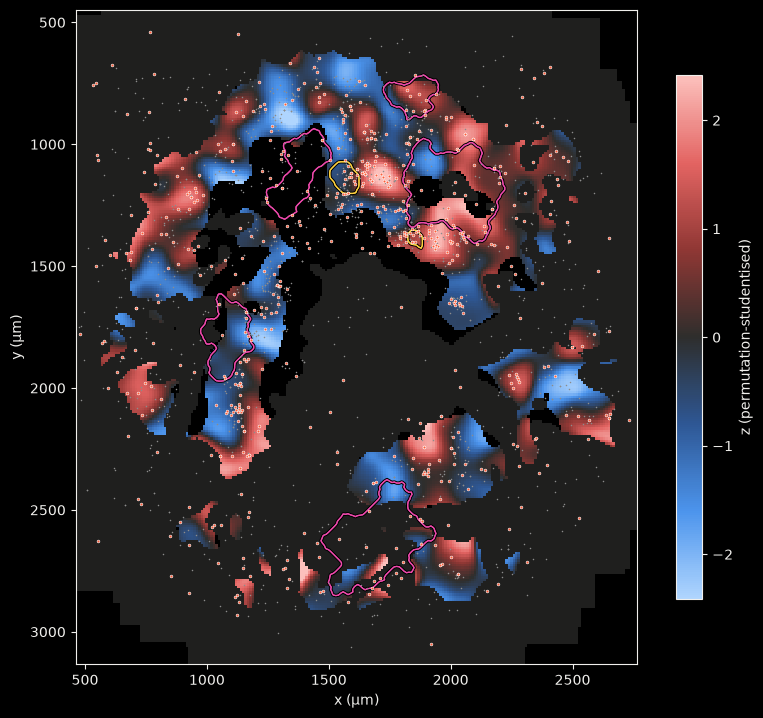

In [20]:
shm_hot = bcr.shm_hotspots(units, tissue=tissue, grid=grid, n_perm=1000, rng=0)
print(shm_hot)
fig, ax = plt.subplots(figsize=(10, 8.5))
pl.shm_share_map(shm_hot, csr=csr, units=units, outlines={"germinal centre": gc_mask}, ax=ax, s=4)
plt.show()

No pixel passes the family-wise threshold (largest z 3.1 against a threshold of 4.0): the mutated share varies over the
node, but not beyond what the isotypes of its 1,852 evaluable loci predict, and the excess in GCs found above is
spread over several of them.

**Mutation spectrum and selection** (`bcr.spectrum`, `bcr.selection`) need more than counts: the germline sequence
around every site (AID hotspot motifs such as WRCY) and the codon frame with IMGT region boundaries (CDR vs FWR). The
MiXCR mutation strings only give the mutated bases, so these tests are not applicable to the GEO tables. Re-aligning
the GEO consensus reads (`GSM8727840_D21_ONT_concensus.fasta.gz`) with IgBLAST (`bcr.run_igblast`, then Change-O for
IMGT-gapped germlines) gives the full alignments they need.

## 6. Lineage trees in tissue

`bcr.build_trees` builds germline-rooted maximum-parsimony trees from aligned sequences of one clone and their clonal
germline (`sequence_alignment`, `germline_alignment_d_mask`). The MiXCR substitutions give an equivalent input: for
each clone, take every V position that is substituted in at least one molecule; the germline base there is known, and
each molecule reads either its substitution, the germline base (position covered, not mutated) or N (not covered).
Positions that never change carry no information for parsimony, so trees on these columns are trees on the whole V
segment.

We build trees for the 32 clones with ≥ 15 molecules, using only molecules with the clone's main V gene; identical
sequences with the same isotype and GC membership collapse into one tip.

In [21]:
def clone_alignment(group):
    """Germline and molecule strings over the V positions substituted in any molecule of one clone."""
    alignments = [v_alignment(s) for s in group["allVAlignments"]]
    germ = {p: g for _, _, subs in alignments for p, (g, _) in subs.items()}
    sites = sorted(germ)
    seqs = ["".join(subs[p][1] if p in subs else (germ[p] if lo <= p < hi else "N") for p in sites)
            for lo, hi, subs in alignments]
    return "".join(germ[p] for p in sites), seqs


m = igh[igh["allVAlignments"].notna() & (igh["isotype"] != "unknown")].copy()
m["v_gene"] = m["v_call"].str.replace(r"\*.*", "", regex=True)
m = m[m["v_gene"] == m.groupby("clone_id")["v_gene"].transform(lambda s: s.mode().iat[0])]
m["in_gc"] = m["region"].eq("GC")
big = m.groupby("clone_id").size().loc[lambda s: s >= 15].index
tips = []
for clone, g in m[m["clone_id"].isin(big)].groupby("clone_id"):
    germ, seqs = clone_alignment(g)
    tips.append(g.assign(germline_alignment_d_mask=germ, sequence_alignment=seqs, sequence_id=g["spot_id"] + ":" + g["umi"]))
tips = pd.concat(tips, ignore_index=True)
trees = bcr.build_trees(tips, traits=("isotype", "in_gc"), filter_stop=False, rng=0)
print(trees)
trees.summary().sort_values("tips", ascending=False).head(8)

LineageTrees(32 trees)


,clone_id,tips,nodes,method,length
19,42,30,61,parsimony,57.0
18,34,26,53,parsimony,40.0
22,54,25,51,parsimony,47.0
20,45,20,41,parsimony,57.0
25,62,20,41,parsimony,32.0
27,77,18,37,parsimony,52.0
23,59,18,37,parsimony,38.0
26,75,18,37,parsimony,57.0


(`filter_stop=False` because these strings are not in reading frame.) `bcr.tip_table` gives one row per molecule
with its tree tip, its depth in the tree (substitutions from the germline along the tree) and every column of the
input, positions included. One tree next to its tissue positions:

clone 59: 33 molecules, 8 in GCs


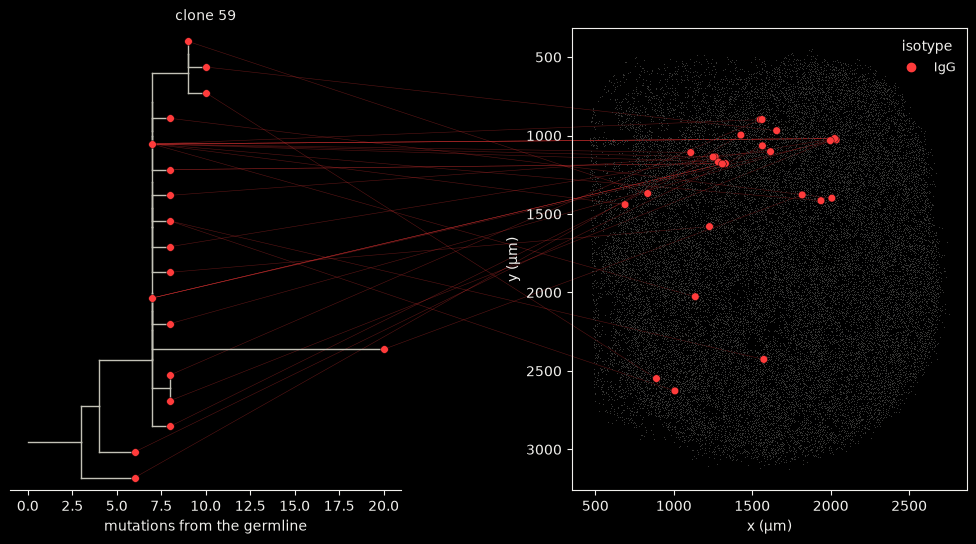

In [22]:
tip_tab = bcr.tip_table(trees)
gc_tips = tip_tab.groupby("clone_id")["in_gc"].sum()
show_clone = gc_tips.idxmax()
print(f"clone {show_clone}: {int((tip_tab.clone_id == show_clone).sum())} molecules, {int(gc_tips.max())} in GCs")
fig = pl.tree_tissue(trees[show_clone], tip_tab[tip_tab["clone_id"] == show_clone], color_key="isotype",
                     background=beads)
plt.show()

Do the tips of a tree sit in GCs more often than their isotypes predict? `tl.tip_region_test` gives each tip the GC
share of all IGH loci of its isotype (the reference), sums these chances per tree and compares the observed GC tips
with the exact Poisson-binomial distribution; molecules of one locus count once (`unit_key`).

In [23]:
reference = units[units["isotype"] != "unknown"].assign(in_gc=lambda d: d["region"].eq("GC"))
trt = tl.tip_region_test(tip_tab, region_key="in_gc", covariate_key="isotype", reference=reference, unit_key="locus_id")
print(trt)
trt.table.sort_values("p_value").head(8)

TestResult(tip_region_test: n_trees=32, n_significant=0, statistic=41, expected=37.88, p_value=0.3223; table 32×9)


,tree,n_tips,statistic,expected,ratio,p_value,n_perm,q_value,significant
4,125,17,5,1.269710,3.937908,0.006710,0,0.214704,False
23,59,22,4,1.643154,2.434343,0.077194,0,0.869601,False
8,139,14,3,1.045643,2.869048,0.081525,0,0.869601,False
9,160,10,2,0.746888,2.677778,0.168469,0,1.000000,False
21,48,20,3,1.496445,2.004751,0.185091,0,1.000000,False
26,75,21,3,1.573803,1.906210,0.205385,0,1.000000,False
17,241,13,2,0.970954,2.059829,0.252944,0,1.000000,False
31,96,13,2,0.970954,2.059829,0.252944,0,1.000000,False


Over the 32 trees, 41 tip loci lie in GCs against 37.9 expected from their isotypes (p = 0.32), and no single tree is
concentrated in GCs after correcting for 32 trees (the smallest q is 0.21, for a tree with 5 GC tips against 1.3
expected). At day 21 the large clones have spread out of their GCs: their members sit mostly in the plasma-cell area
and the follicles.

## Summary

| Question | Function | D21 answer |
|---|---|---|
| Switched-share hotspots | `bcr.csr_hotspots` | 2 small hotspots in a node that is 89% switched |
| GCs richer in switched loci? | `bcr.region_test(mark="switched")` | barely (ratio 1.01, p = 0.04 pooled); no single GC after BH |
| Isotypes mixed within clones? | `bcr.csr_transitions` | less than random labelling; neighbouring IgG subclasses most |
| Switched members more mutated? | `bcr.csr_transitions(null="within")` | yes, IgG > IgM within 11 clones (p = 0.01) |
| GCs richer in mutated loci, isotype-matched? | `bcr.region_test(mark="mutated", match_by="isotype")` | yes, pooled (ratio 1.32, p = 0.047); no single GC after BH |
| Mutated-share hotspots | `bcr.shm_hotspots` (isotype-matched) | none |
| Lineage tips concentrated in GCs? | `bcr.build_trees` + `tl.tip_region_test` | no (41 GC tips vs 37.9 expected) |

**Caveats.** Mutation counts here come from the 3' half of V (about 150 nt) in single nanopore consensus reads, so
they are noisier than full-length Illumina contigs, and spectrum or selection need re-alignment. Trees built only from
substituted positions have the right topology for parsimony but ignore insertions and deletions. GCs are called from
GEX markers in 10 µm beads, so a bead at a GC edge can be part GC, part follicle.

In [24]:
print(f"notebook run time: {time.time() - t_start:.0f} s")

notebook run time: 21 s
